# Gráficas explicativas de las variables

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv("../src/data/HU4_EDA.csv")
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis (mg),forma_farmaceutica_simplificada,estado_aut,estado_rev,vias_administracion,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,Indicador_Riesgo,Estado,Precio venta al público con IVA,Tratamiento de larga duración
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorios Cinfa S.A.,Laboratorios Cinfa S.A.,12.5,COMPRIMIDO,2014-04-16 12:43:40,2014-04-16 12:43:40,VÍA ORAL,1,1,1,1,636,1,14,ALTA,32.085076,NO
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",ALMOTRIPTAN,Laboratorios Normon S.A.,Laboratorios Normon S.A.,12.5,COMPRIMIDO,2013-06-18 06:25:10,2013-06-18 06:25:10,VÍA ORAL,1,1,1,1,662,1,13,ALTA,19.530000,NO
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",ALMOTRIPTAN,Laboratorio Stada S.L.,Laboratorio Stada S.L.,12.5,COMPRIMIDO,2014-01-26 23:00:00,2014-01-26 23:00:00,VÍA ORAL,1,1,1,1,650,1,13,ALTA,19.530000,NO
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,IBUPROFENO,Kern Pharma S.L.,Kern Pharma S.L.,600.0,SOLUCIÓN,2008-01-29 23:00:00,2008-01-29 23:00:00,VÍA ORAL,1,1,0,1,1375,0,12,BAJA POR NO COMERCIALIZAR,2.500000,NO
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,IBUPROFENO,Laboratorio Stada S.L.,Laboratorio Stada S.L.,600.0,COMPRIMIDO,2013-06-10 22:00:00,2013-06-10 22:00:00,VÍA ORAL,1,1,0,1,1238,0,13,ALTA,1.970000,NO


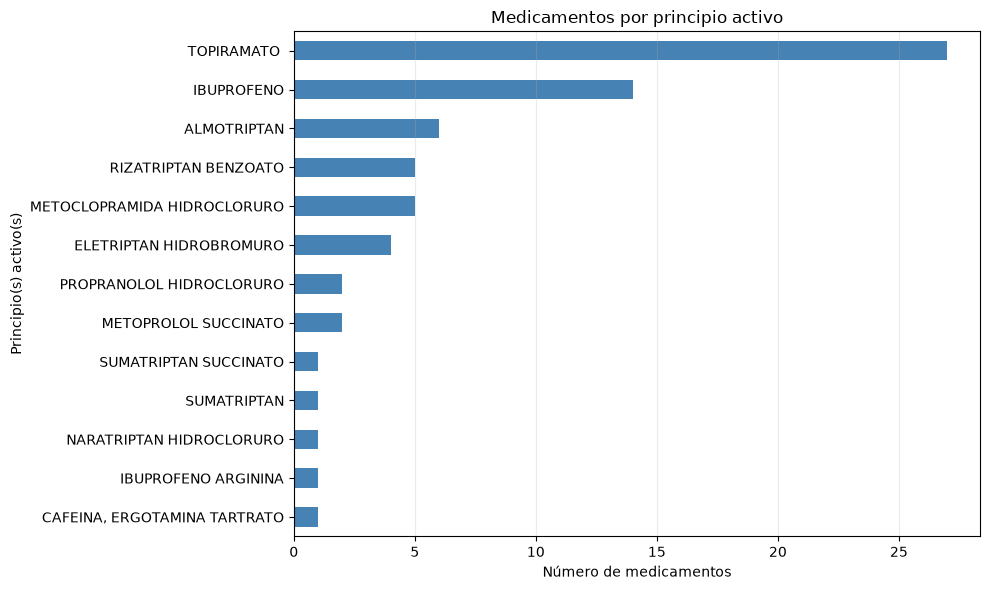

In [15]:
medicamentos_por_activo = df.groupby("pactivos").size().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
medicamentos_por_activo.plot(kind="barh", ax=ax, color="steelblue")
ax.set(title="Medicamentos por principio activo", xlabel="Número de medicamentos", ylabel="Principio(s) activo(s)")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

En esta grafica estamos midiendo el número de medicamentos contra la migraña que utilizan cada principio activo con el fin de saber cuales son más populares.
En este caso parece ser que los más utilizados son el Toripamato, Ibuprofeno y Almotriptan.

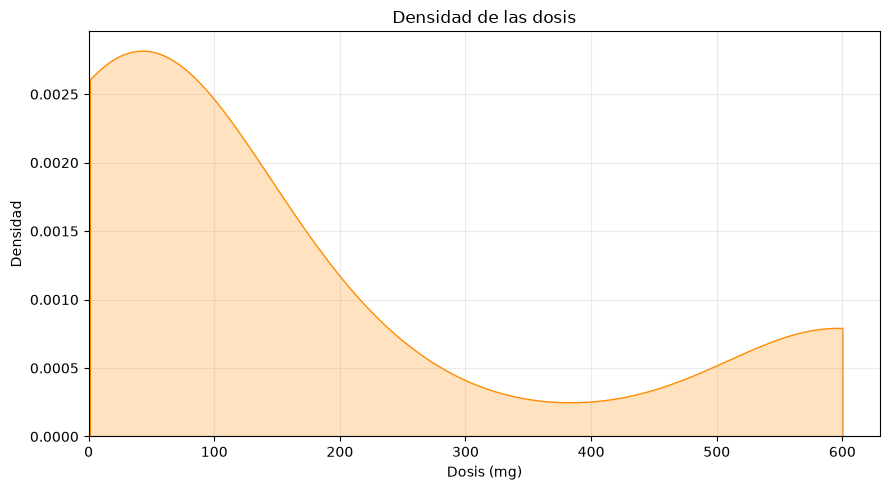

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=df, x="dosis (mg)", fill=True, cut=0, ax=ax, color="darkorange")
ax.set(title="Densidad de las dosis", xlabel="Dosis (mg)", ylabel="Densidad", xlim=(0, None))
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

En esta grafica podemos ver como la densidad de las dosis sigue una distribucion bimodal con un maximo absoluto en 50mg (aproximadamente) y uno relativo en 600mg. Esto se debe a que desde 50mg a 400mg se produce una caida de la densidad a medida que aumenta la dosis y la inversa de 400mg a 600mg. El minimo absoluto esta ligeramente por debajo de 400mg.

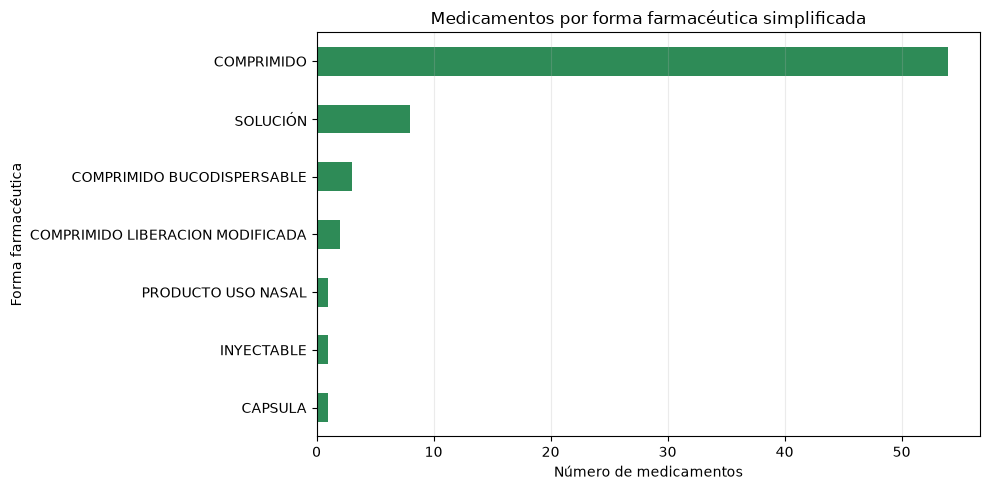

In [17]:
medicamentos_por_forma = df.groupby("forma_farmaceutica_simplificada").size().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
medicamentos_por_forma.plot(kind="barh", ax=ax, color="seagreen")
ax.set(title="Medicamentos por forma farmacéutica simplificada", xlabel="Número de medicamentos", ylabel="Forma farmacéutica")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Este grafico nos da el numero de medicamentos por su forma farmaceutica. SE ve clramente que la aplastante mayoria son por comprimido que es mayor que la suma de todos los demas formatos juntos.

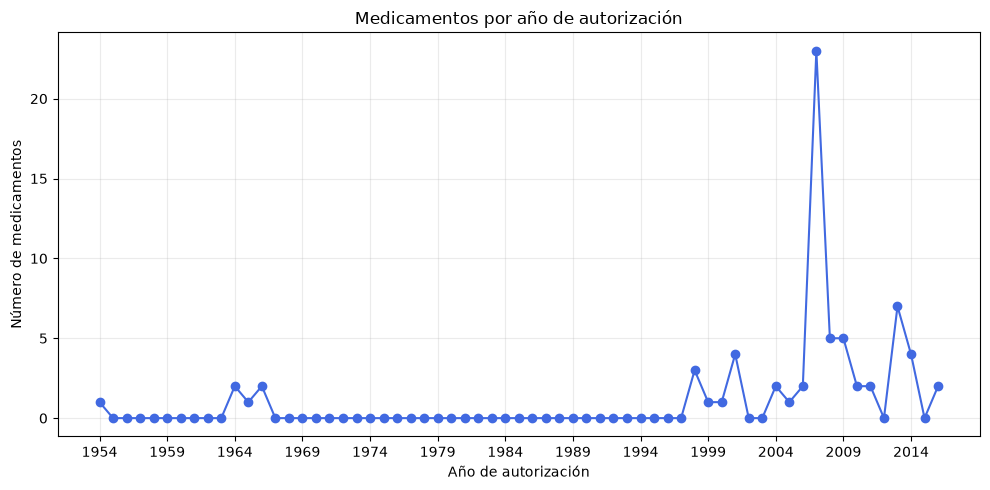

In [18]:
columna_fecha = df["estado_aut"]
fechas_autorizacion = pd.to_datetime(
    columna_fecha,
    errors="coerce",
    unit="ms" if pd.api.types.is_numeric_dtype(columna_fecha) else None,
)
conteo_anual = fechas_autorizacion.dropna().dt.year.value_counts().sort_index()
if conteo_anual.empty:
    raise ValueError("No hay fechas de autorización que se puedan interpretar.")
conteo_anual = conteo_anual.reindex(range(conteo_anual.index.min(), conteo_anual.index.max() + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(conteo_anual.index, conteo_anual.values, marker="o", color="royalblue")
ax.set(title="Medicamentos por año de autorización", xlabel="Año de autorización", ylabel="Número de medicamentos")
ax.set_xticks(conteo_anual.index[::max(1, len(conteo_anual) // 12)])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

Aqui se puede observar como desde 1954 hasta 1997 solo se autorizaron 3 medicamentos contra la migraña, la tendencia cambia a partir de 1998 cuando se aprobaron dos medicamentos ese mismo año y se aprobaron medicamentos todos los años posteriores menos 4. Con un pico en 2007.

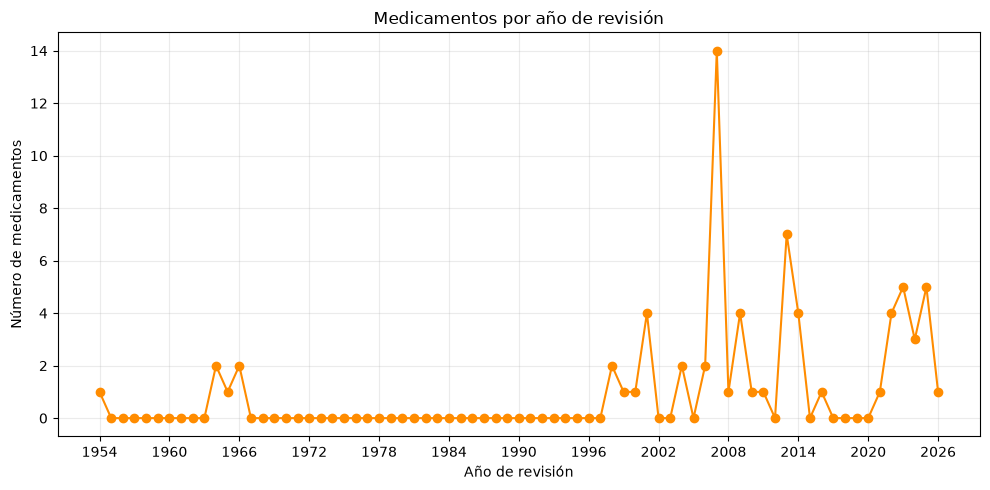

In [19]:
columna_fecha = df["estado_rev"]
fechas_revision = pd.to_datetime(
    columna_fecha,
    errors="coerce",
    unit="ms" if pd.api.types.is_numeric_dtype(columna_fecha) else None,
)
conteo_anual = fechas_revision.dropna().dt.year.value_counts().sort_index()
if conteo_anual.empty:
    raise ValueError("No hay fechas de revisión que se puedan interpretar.")
conteo_anual = conteo_anual.reindex(range(conteo_anual.index.min(), conteo_anual.index.max() + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(conteo_anual.index, conteo_anual.values, marker="o", color="darkorange")
ax.set(title="Medicamentos por año de revisión", xlabel="Año de revisión", ylabel="Número de medicamentos")
ax.set_xticks(conteo_anual.index[::max(1, len(conteo_anual) // 12)])
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

Es practicamente identica a la anterior, refleja cuantos medicamentos se revisaban cada año antes de su aprobacion o que esta fuera denegada.

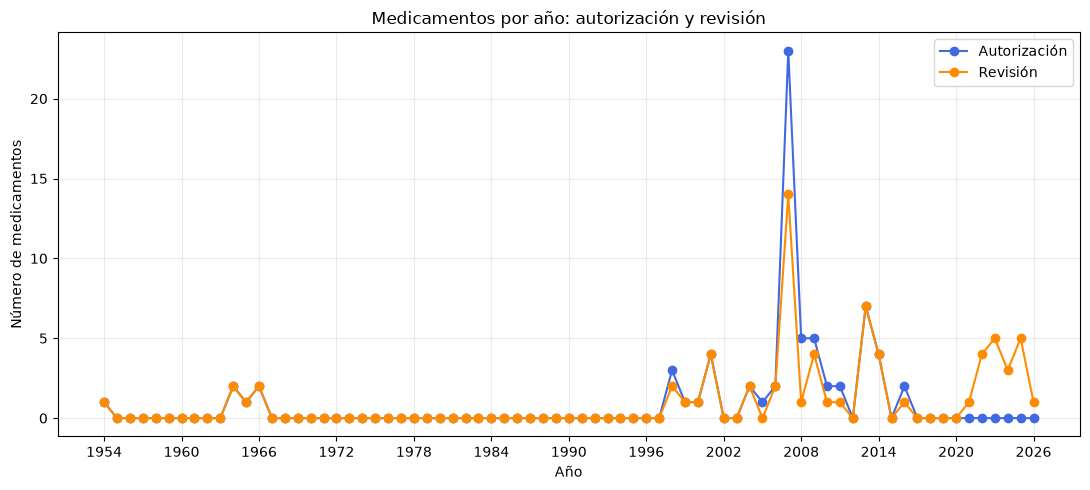

In [32]:
# Compara las frecuencias anuales de autorización y revisión en una misma escala.
fechas_autorizacion = pd.to_datetime(
    df["estado_aut"],
    errors="coerce",
    unit="ms" if pd.api.types.is_numeric_dtype(df["estado_aut"]) else None,
)
fechas_revision = pd.to_datetime(
    df["estado_rev"],
    errors="coerce",
    unit="ms" if pd.api.types.is_numeric_dtype(df["estado_rev"]) else None,
)
conteo_autorizacion = fechas_autorizacion.dropna().dt.year.value_counts()
conteo_revision = fechas_revision.dropna().dt.year.value_counts()
if conteo_autorizacion.empty or conteo_revision.empty:
    raise ValueError("Se necesitan fechas válidas de autorización y revisión para comparar.")

anios = range(
    min(conteo_autorizacion.index.min(), conteo_revision.index.min()),
    max(conteo_autorizacion.index.max(), conteo_revision.index.max()) + 1,
)
conteo_autorizacion = conteo_autorizacion.reindex(anios, fill_value=0)
conteo_revision = conteo_revision.reindex(anios, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(conteo_autorizacion.index, conteo_autorizacion.values, marker="o", label="Autorización", color="royalblue")
ax.plot(conteo_revision.index, conteo_revision.values, marker="o", label="Revisión", color="darkorange")
ax.set(title="Medicamentos por año: autorización y revisión", xlabel="Año", ylabel="Número de medicamentos")
ax.set_xticks(list(anios)[::max(1, len(anios) // 12)])
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Como comentaba anteriormente ambas graficas son muy parecidas con ciertas excepciones hasta 2020, donde ninguno de los medicamnetos posteriores a ese año que fueron revisados fueron autorizados.

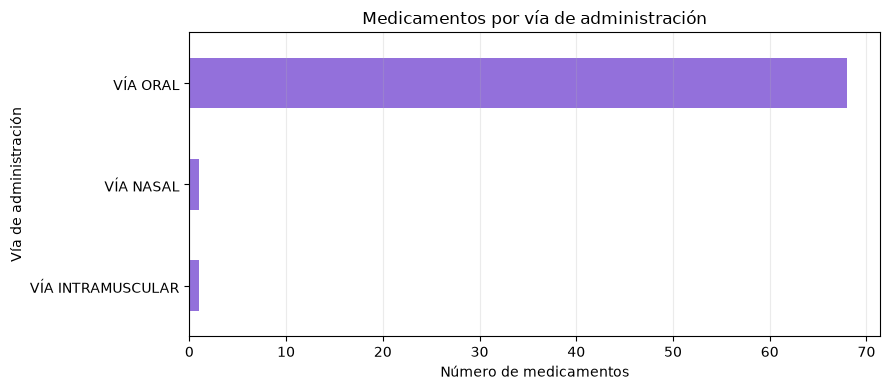

In [20]:
medicamentos_por_via = df.groupby("vias_administracion").size().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
medicamentos_por_via.plot(kind="barh", ax=ax, color="mediumpurple")
ax.set(title="Medicamentos por vía de administración", xlabel="Número de medicamentos", ylabel="Vía de administración")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Se ve claramnete que casi todos los medicamentos contra la migraña se ingieren via oral.

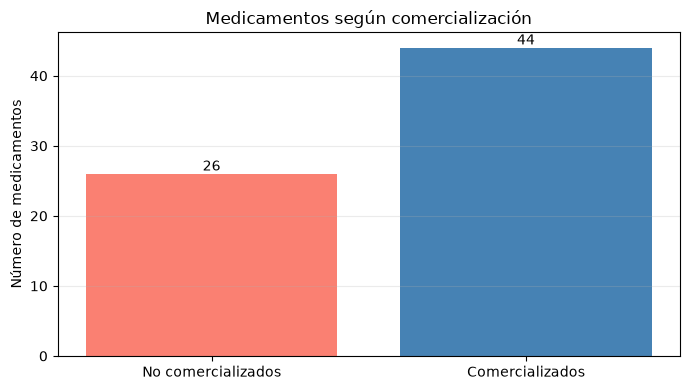

In [21]:
conteo = df["comercializado"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["No comercializados", "Comercializados"], conteo.values, color=["salmon", "steelblue"])
ax.set(title="Medicamentos según comercialización", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

44 medicamentos fueron comercializados y 26 no.

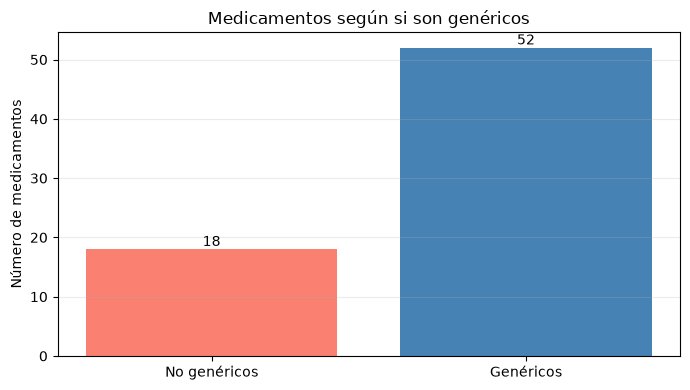

In [22]:
conteo = df["generico"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["No genéricos", "Genéricos"], conteo.values, color=["salmon", "steelblue"])
ax.set(title="Medicamentos según si son genéricos", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

52 medicamentos contra la migraña son genericos y 18 no.

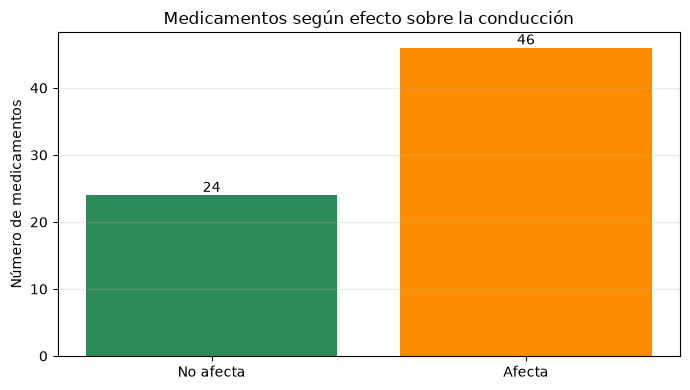

In [23]:
conteo = df["afecta_conduccion"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["No afecta", "Afecta"], conteo.values, color=["seagreen", "darkorange"])
ax.set(title="Medicamentos según efecto sobre la conducción", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

46 medicamentos contra la migraña afectan a la conduccion y 24 no.

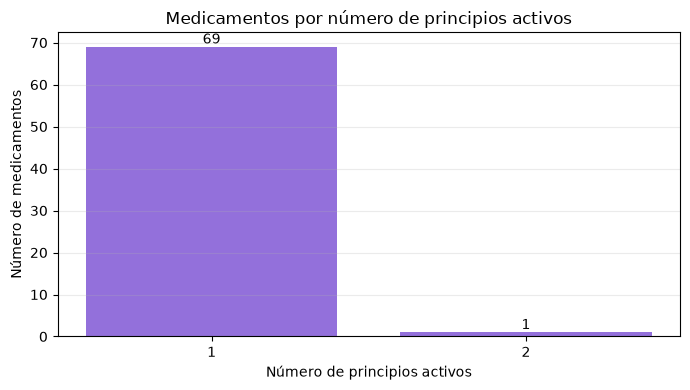

In [24]:
conteo = df["num_principios_activos"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conteo.index.astype(str), conteo.values, color="mediumpurple")
ax.set(title="Medicamentos por número de principios activos", xlabel="Número de principios activos", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

Todos los medicamentos menos 1 tienen solo un principio activo.

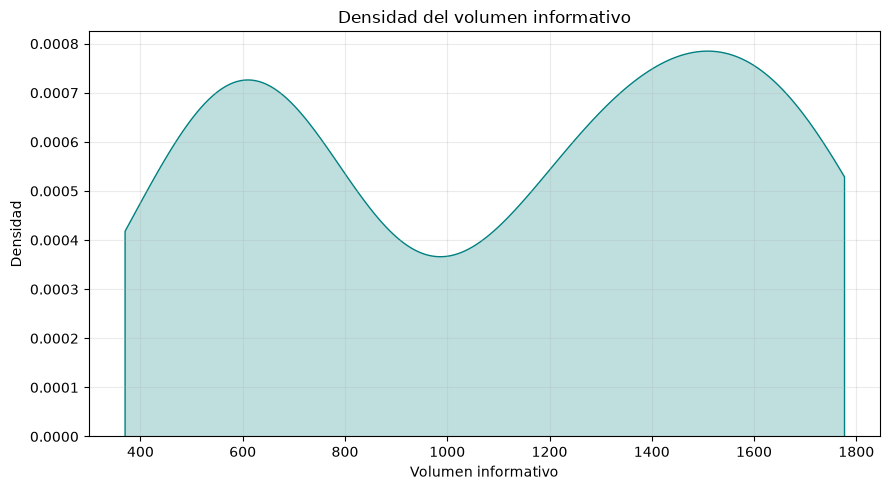

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=df, x="Volumen_Informativo", fill=True, cut=0, ax=ax, color="teal")
ax.set(title="Densidad del volumen informativo", xlabel="Volumen informativo", ylabel="Densidad")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

La densidad del volumen informativo sigue una forma bimodal con maximos en 600 y 1500.

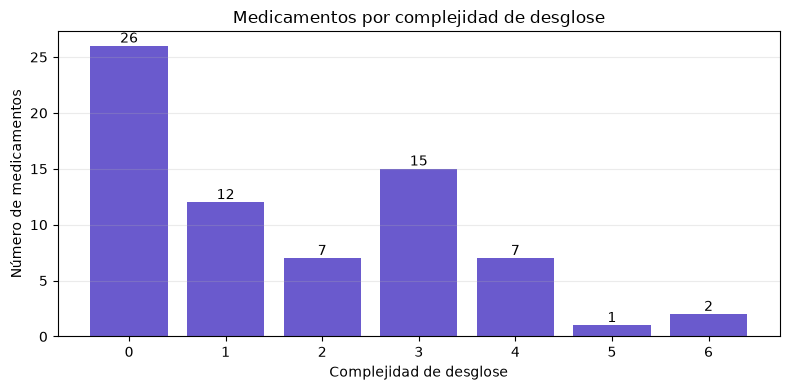

In [26]:
conteo = df["Complejidad_Desglose"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(conteo.index.astype(str), conteo.values, color="slateblue")
ax.set(title="Medicamentos por complejidad de desglose", xlabel="Complejidad de desglose", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

Aqui tenemos un histograma con el numero de medicamentos por complejidad del desglose.

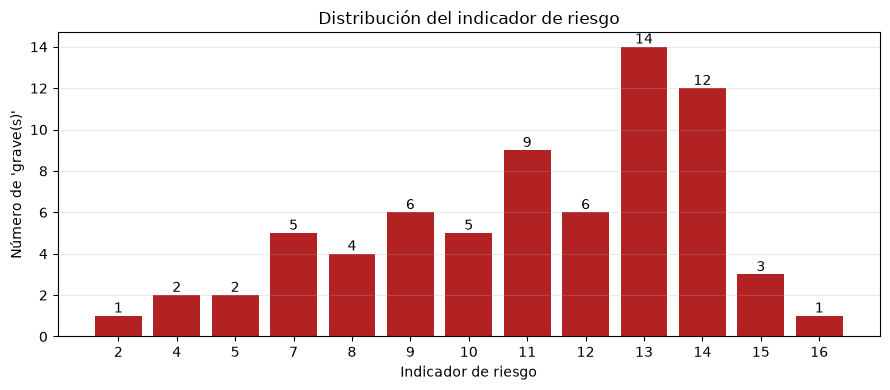

In [34]:
conteo = df["Indicador_Riesgo"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(conteo.index.astype(str), conteo.values, color="firebrick")
ax.set(title="Distribución del indicador de riesgo", xlabel="Indicador de riesgo", ylabel="Número de 'grave(s)'")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

Podemos ver en este histograma que el indicador de riesgo sube cuanto más casos grave hay.

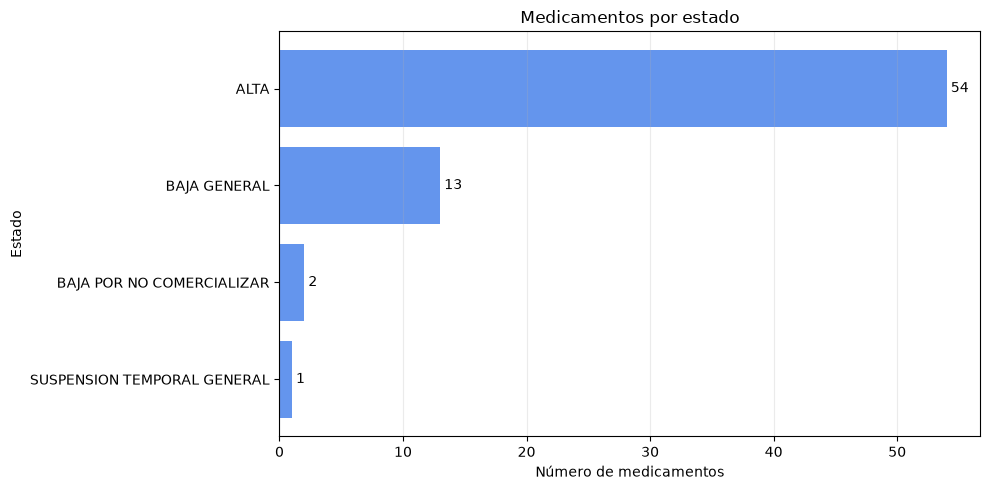

In [28]:
conteo = df["Estado"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(conteo.index, conteo.values, color="cornflowerblue")
ax.set(title="Medicamentos por estado", xlabel="Número de medicamentos", ylabel="Estado")
ax.bar_label(ax.containers[0], padding=3)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Se puede observar que la mayoria de medicamentos para la migraña estan de alta (53), 13 de baja general, 2 de baja por no comercializarse y uno suspendido temporalmente.

/var/folders/m1/ksyvty913jdbvxylmzlj3_d00000gn/T/ipykernel_61845/419055433.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(precios, vert=False, showmeans=True)


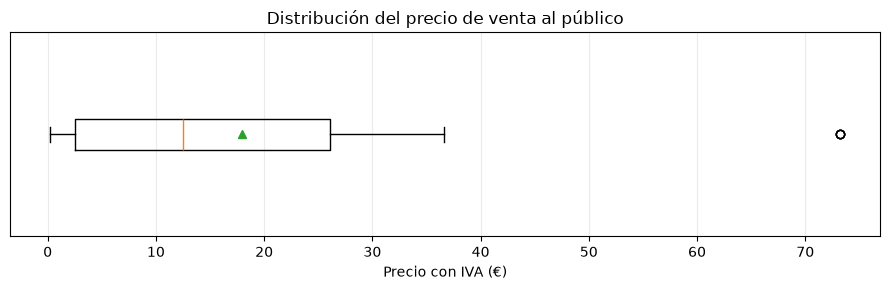

In [29]:
precios = df["Precio venta al público con IVA"].dropna()
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(precios, vert=False, showmeans=True)
ax.set(title="Distribución del precio de venta al público", xlabel="Precio con IVA (€)", yticks=[])
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Aqui tenemos un grafico de vela con el precio de venta al publico con IVA incluido. El precio típico ronda los 13 € (más o menos), la mitad está entre un poco más de 0 euros y 26 €, y aparece un valor atípico por encima de 70 €.

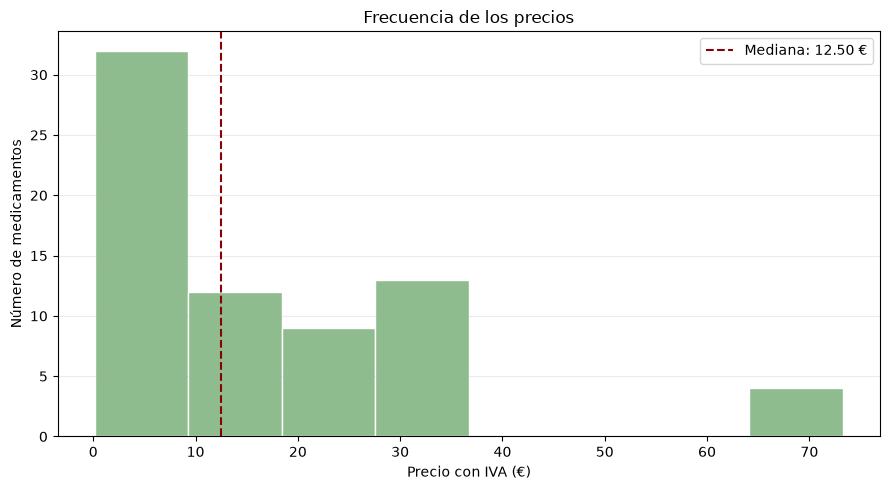

In [30]:
precios = df["Precio venta al público con IVA"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(precios, bins="auto", color="darkseagreen", edgecolor="white")
ax.axvline(precios.median(), color="darkred", linestyle="--", label=f"Mediana: {precios.median():.2f} €")
ax.set(title="Frecuencia de los precios", xlabel="Precio con IVA (€)", ylabel="Número de medicamentos")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

La mediana del precion con iva esta en 12.5€. Con la excepcion del outlier en 70€ los precios se situan entre 0€ y 37€(mas o menos), con la moda entre 0€ y 10€.

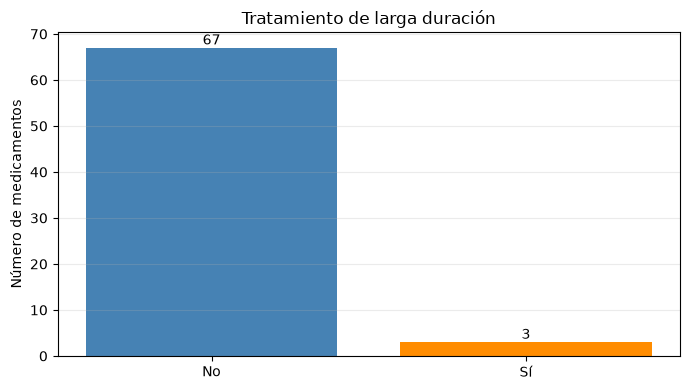

In [35]:
conteo = df["Tratamiento de larga duración"].value_counts().reindex(["NO", "SI"], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["No", "Sí"], conteo.values, color=["steelblue", "darkorange"])
ax.set(title="Tratamiento de larga duración", ylabel="Número de medicamentos")
ax.bar_label(ax.containers[0])
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

3 medicamentos son para tratamiento de larga duracion y 67 no.